# MNIST handwritten digits - feed-forward neural network

Study preparation. Run all cells from top to bottom. Outputs below are from a fresh Python execution, not the supplied saved outputs. Full original epoch counts and datasets are preserved. Numeric results can vary across software versions.

## Cell 1: Set up reproducibility

Set fixed seeds for Python, NumPy and TensorFlow. Limit CPU thread use so this runs without a GPU. A seed reduces randomness, but different versions/hardware may still change results.

In [1]:
# Reproducible CPU-friendly setup. Colab already includes the main libraries.
import os, random
os.environ["TF_NUM_INTRAOP_THREADS"] = "2"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
import numpy as np
import tensorflow as tf
random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("Execution device: CPU")


TensorFlow: 2.16.1
Execution device: CPU

## Cell 2: Import libraries

TensorFlow/Keras builds and trains the network; NumPy handles arrays; Matplotlib draws images and learning curves. Pandas is imported by the original practical but is not needed here.

In [2]:
#importing necessary libraries
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
%matplotlib inline

## Cell 3: Load MNIST

Load 60,000 training images and 10,000 test images. Each image is 28 x 28 grayscale; the integer label is the digit 0 to 9. The first run downloads the dataset.

In [3]:
#import dataset and split into train and test data
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

## Cell 4: Inspect an image

Display the second training image. Looking at examples helps confirm that the data loaded correctly.

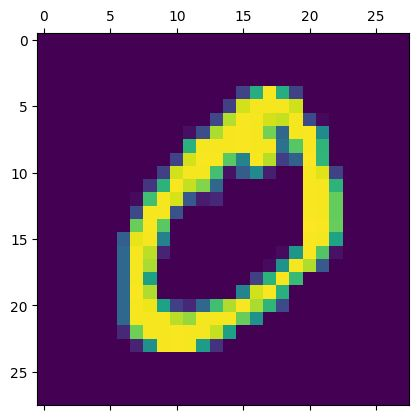

In [4]:
plt.matshow(x_train[1])

## Cell 5: Display inverted grayscale

Subtract pixel values from 255 to invert the grayscale safely. The original negative sign on uint8 data wraps around rather than performing a clean inversion. This affects only visualization, not training.

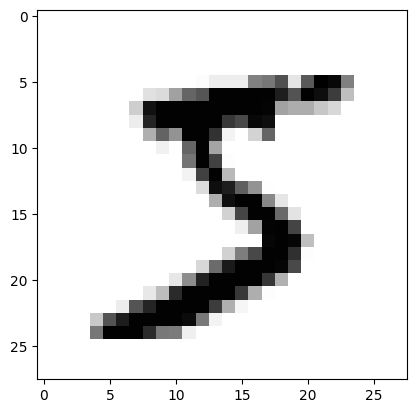

In [5]:
# Show an inverted grayscale image without uint8 arithmetic overflow.
plt.imshow(255 - x_train[0], cmap="gray")
plt.show()

## Cell 6: Normalize pixels

Divide pixel values by 255, changing the range from 0..255 to 0..1. This puts input values on a smaller scale for gradient-based training.

In [6]:
x_train = x_train / 255
x_test = x_test / 255

## Cell 7: Build the feed-forward network

Flatten converts 28 x 28 into 784 inputs. Dense(128, relu) learns nonlinear features. Dense(10, softmax) outputs one probability per digit. Parameters: 784*128+128 + 128*10+10 = 101,770.

In [7]:
model = keras.Sequential([
keras.layers.Flatten(input_shape=(28, 28)),
keras.layers.Dense(128, activation="relu"),
keras.layers.Dense(10, activation="softmax")
])

model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Cell 8: Compile the network

SGD updates weights using gradients. Sparse categorical cross-entropy matches integer class labels; do not one-hot encode labels unless you change the loss. Accuracy is the fraction of correct class predictions.

In [8]:
model.compile(optimizer="sgd",
loss="sparse_categorical_crossentropy",
metrics=['accuracy'])

## Cell 9: Train for 10 epochs

Each epoch makes a pass through all training samples. Keras uses batch size 32 by default. This original practical uses the official test set as validation_data: no test gradients are taken, but repeated inspection makes it unsuitable as a pristine final holdout. For a serious experiment use a separate validation split.

In [9]:
history=model.fit(x_train,
y_train,validation_data=(x_test,y_test),epochs=10)

Epoch 1/10
   1/1875 ━━━━━━━━━━━━━━━━━━━━ 6:34 210ms/step - accuracy: 0.0625 - loss: 2.4478  45/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.1589 - loss: 2.2607      88/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.2455 - loss: 2.1548 128/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.3099 - loss: 2.0686 168/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.3603 - loss: 1.9929 208/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4010 - loss: 1.9250 248/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4347 - loss: 1.8631 290/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.4645 - loss: 1.8033 332/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.4898 - loss: 1.7489 373/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5109 - loss: 1.7003 415/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5297 - loss: 1.6546 457/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5464 - loss: 1.6126 499/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5613 - loss:

## Cell 10: Evaluate

Evaluate loss and accuracy on the test set. The fresh run prints rounded loss and accuracy; these are measured results, not promised values for every run.

In [10]:
test_loss,test_acc=model.evaluate(x_test,y_test)
print("Loss=%.3f" %test_loss)
print("Accuracy=%.3f" %test_acc)

  1/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9688 - loss: 0.1676 52/313 ━━━━━━━━━━━━━━━━━━━━ 0s 985us/step - accuracy: 0.9504 - loss: 0.1650104/313 ━━━━━━━━━━━━━━━━━━━━ 0s 979us/step - accuracy: 0.9440 - loss: 0.1901156/313 ━━━━━━━━━━━━━━━━━━━━ 0s 976us/step - accuracy: 0.9421 - loss: 0.1969209/313 ━━━━━━━━━━━━━━━━━━━━ 0s 972us/step - accuracy: 0.9418 - loss: 0.1972263/313 ━━━━━━━━━━━━━━━━━━━━ 0s 964us/step - accuracy: 0.9427 - loss: 0.1934313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 997us/step - accuracy: 0.9516 - loss: 0.1617
Loss=0.162
Accuracy=0.952

## Cell 11: Choose a test image

Pick a random test index and display its image. The fixed seed makes this example more repeatable.

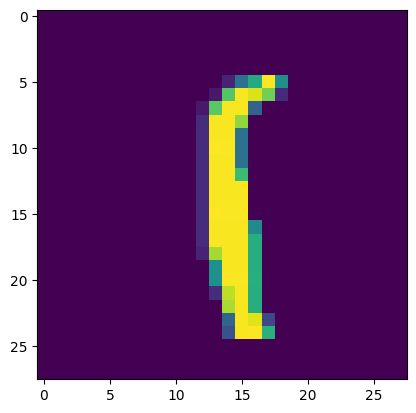

In [11]:
n=random.randint(0,9999)
plt.imshow(x_test[n])
plt.show()

## Cell 12: Inspect training data compactly

Print the shape and a 5 x 5 corner of the first image instead of flooding the notebook with the full training array. This does not change the data or model.

In [12]:
print("x_train shape:", x_train.shape)
print("First image (top-left 5x5):")
print(x_train[0, :5, :5])

x_train shape: (60000, 28, 28)
First image (top-left 5x5):
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]

## Cell 13: Inspect test data compactly

Print the test shape and sample corner. The test data is normalized in exactly the same way as the training data.

In [13]:
print("x_test shape:", x_test.shape)
print("First image (top-left 5x5):")
print(x_test[0, :5, :5])

x_test shape: (10000, 28, 28)
First image (top-left 5x5):
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]

## Cell 14: Predict probabilities

Predict a 10-element softmax vector for each test image and show the selected image. Position 0 represents digit 0, position 1 digit 1, and so on. The largest probability gives the predicted digit (np.argmax(predicted_value[n])).

  1/313 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step 87/313 ━━━━━━━━━━━━━━━━━━━━ 0s 587us/step179/313 ━━━━━━━━━━━━━━━━━━━━ 0s 567us/step259/313 ━━━━━━━━━━━━━━━━━━━━ 0s 587us/step313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 654us/step

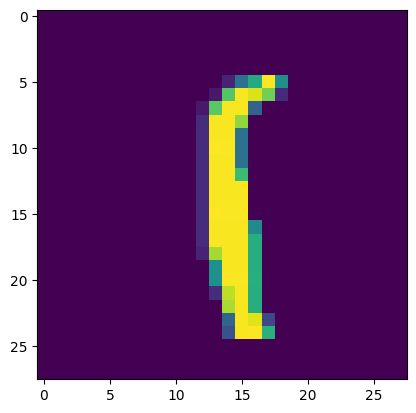

[3.6157016e-07 9.8982835e-01 2.3489875e-04 2.0368428e-03 4.5812190e-05
 6.3676515e-04 1.7222638e-04 3.9606708e-05 6.7728753e-03 2.3233175e-04]

In [14]:
predicted_value=model.predict(x_test)
plt.imshow(x_test[n])
plt.show()

print(predicted_value[n])

## Cell 15: Plot accuracy

Training accuracy measures the training set; validation accuracy measures the test-as-validation set used above. Compare their trends to spot a growing generalization gap.

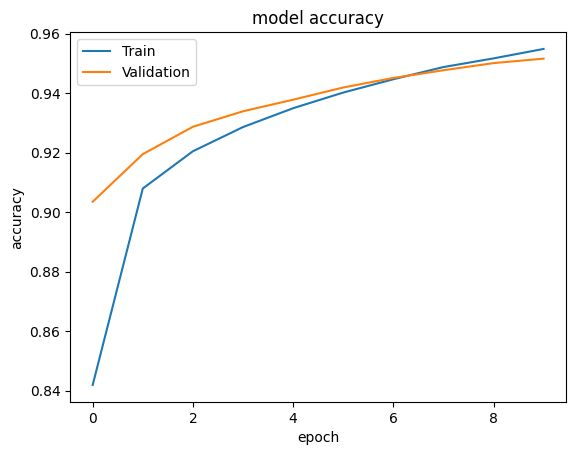

In [15]:
# history.history()
history.history.keys()
# dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

## Cell 16: Plot loss

Cross-entropy measures prediction error. Lower is better. A falling training loss with rising validation loss is a warning sign of overfitting.

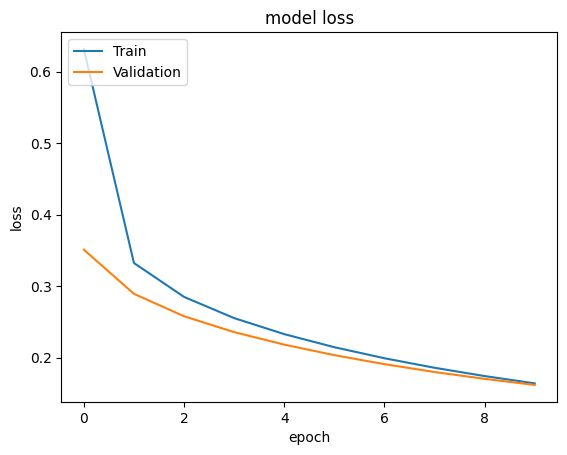

In [16]:
# history.history()
history.history.keys()
# dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()